# 01 — Regressão: California Housing

**O que este notebook mostra**
1. O motor de autodiff em uma expressão pequena: grafo, backward e conferência por diferenças finitas.
2. Um MLP treinado para prever o preço médio das casas (California Housing, 8 atributos).
3. Monitoramento: custo e R² por época (treino e validação), histogramas de ativações e gradientes.
4. Regularização L2 feita só compondo operações do motor (nenhuma derivada nova).
5. Exportar → importar → inferir sem treinar (com a padronização junto no arquivo).
6. Resultado final no conjunto de **teste** (usado uma única vez, no fim).

> Por que não Boston Housing? Ele foi removido do scikit-learn (versão 1.2) porque uma das variáveis
> (`B`) foi construída a partir da proporção de pessoas negras no bairro, com uma suposição racista embutida.
> Usamos o California Housing, que é o substituto recomendado.

In [1]:
import numpy as np

from motor import Tensor, imprimir_grafo
from checagem import verificar_gradientes
from rede import MLP
from treino import treinar, metricas_regressao
from exportacao import salvar_modelo, carregar_modelo
from dados import carregar_california
import graficos as g
import graficos_gradientes as gg

MODO_RAPIDO = True   # True: subconjunto dos dados e menos épocas (< 60 s)
g.configurar_estilo()

## 1. O motor em 30 segundos

Expressão: `f = soma( (a @ b + c) * a.sum() )`. O `a` é usado duas vezes (o gradiente precisa **acumular**)
e `c` tem shape `(1, 2)` mas é somado a uma matriz `(2, 2)` (o gradiente precisa **desfazer o broadcasting**).

In [2]:
a = Tensor([[1.0, 2.0], [3.0, 4.0]], nome="a")
b = Tensor([[0.5, -1.0], [2.0, 0.1]], nome="b")
c = Tensor([[1.0, -2.0]], nome="c")

def f():
    return ((a @ b + c) * a.sum()).sum()

saida = f()
imprimir_grafo(saida)
saida.backward()
print("\ndf/dc =", c.grad, " (shape", c.grad.shape, ")")
print("maior erro relativo motor × diferenças finitas:", verificar_gradientes(f, [a, b, c]))

[sum] shape=()
    [*] shape=(2, 2)
        [+] shape=(2, 2)
            [@] shape=(2, 2)
                [folha] 'a' shape=(2, 2)
                [folha] 'b' shape=(2, 2)
            [folha] 'c' shape=(1, 2)
        [sum] shape=()
            [folha] 'a' shape=(2, 2)

df/dc = [[20. 20.]]  (shape (1, 2) )
maior erro relativo motor × diferenças finitas: 3.219395919984993e-10


## 2. Dados

X e y são padronizados (média 0, desvio 1) com estatísticas **só do treino**. Split fixo 70/15/15.

In [3]:
dados = carregar_california(modo_rapido=MODO_RAPIDO)
print("treino:", dados["X_treino"].shape, " validação:", dados["X_val"].shape, " teste:", dados["X_teste"].shape)
print("atributos:", dados["nomes_atributos"])

treino: (4200, 8)  validação: (900, 8)  teste: (900, 8)
atributos: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


## 3. Configuração e treino

Tudo é configurado por dicionários: mudar a arquitetura é mudar `camadas_ocultas`.
Early stopping: guarda os pesos da melhor época na validação.

In [4]:
config_rede = {
    "n_entrada": 8,
    "camadas_ocultas": [64, 32],
    "n_saida": 1,
    "ativacao_oculta": "relu",
    "ativacao_saida": "linear",
    "inicializacao": "he",
    "seed": 42,
}
config_treino = {
    "perda": "mse",
    "metrica": "r2",
    "otimizador": "adam",
    "taxa_aprendizado": 1e-3,
    "epocas": 40 if MODO_RAPIDO else 200,
    "tamanho_lote": 64,
    "paciencia": 10,
    "coletar_a_cada": 10,
}
rede = MLP(config_rede)
historico = treinar(rede, dados, config_treino)

época   1 | perda treino 0.5290 val 0.4981 | r2 treino 0.4710 val 0.4693
época   2 | perda treino 0.3884 val 0.3797 | r2 treino 0.6116 val 0.5954
época   3 | perda treino 0.3408 val 0.3286 | r2 treino 0.6592 val 0.6499


época   4 | perda treino 0.4377 val 0.4017 | r2 treino 0.5623 val 0.5719


época   5 | perda treino 0.3070 val 0.2991 | r2 treino 0.6930 val 0.6813
época   6 | perda treino 0.2825 val 0.2839 | r2 treino 0.7175 val 0.6975
época   7 | perda treino 0.2787 val 0.2765 | r2 treino 0.7213 val 0.7054


época   8 | perda treino 0.4165 val 0.3371 | r2 treino 0.5835 val 0.6408
época   9 | perda treino 0.3418 val 0.3169 | r2 treino 0.6582 val 0.6623
época  10 | perda treino 0.2679 val 0.2629 | r2 treino 0.7321 val 0.7199
época  11 | perda treino 0.2517 val 0.2617 | r2 treino 0.7483 val 0.7212
época  12 | perda treino 0.2446 val 0.2576 | r2 treino 0.7554 val 0.7256


época  13 | perda treino 0.2349 val 0.2533 | r2 treino 0.7651 val 0.7301
época  14 | perda treino 0.2339 val 0.2524 | r2 treino 0.7661 val 0.7310
época  15 | perda treino 0.2397 val 0.2528 | r2 treino 0.7603 val 0.7307
época  16 | perda treino 0.2362 val 0.2463 | r2 treino 0.7638 val 0.7375


época  17 | perda treino 0.2463 val 0.2521 | r2 treino 0.7537 val 0.7313
época  18 | perda treino 0.2532 val 0.2484 | r2 treino 0.7468 val 0.7353
época  19 | perda treino 0.2292 val 0.2431 | r2 treino 0.7708 val 0.7410
época  20 | perda treino 0.2340 val 0.2459 | r2 treino 0.7660 val 0.7380


época  21 | perda treino 0.2654 val 0.2460 | r2 treino 0.7346 val 0.7379
época  22 | perda treino 0.2379 val 0.2487 | r2 treino 0.7621 val 0.7350
época  23 | perda treino 0.2216 val 0.2415 | r2 treino 0.7784 val 0.7427
época  24 | perda treino 0.2322 val 0.2385 | r2 treino 0.7678 val 0.7458
época  25 | perda treino 0.2159 val 0.2409 | r2 treino 0.7841 val 0.7434


época  26 | perda treino 0.2126 val 0.2398 | r2 treino 0.7874 val 0.7445
época  27 | perda treino 0.2129 val 0.2436 | r2 treino 0.7871 val 0.7404
época  28 | perda treino 0.2095 val 0.2366 | r2 treino 0.7905 val 0.7479
época  29 | perda treino 0.2191 val 0.2482 | r2 treino 0.7809 val 0.7355
época  30 | perda treino 0.2092 val 0.2324 | r2 treino 0.7908 val 0.7524


época  31 | perda treino 0.2084 val 0.2390 | r2 treino 0.7916 val 0.7453
época  32 | perda treino 0.2072 val 0.2362 | r2 treino 0.7928 val 0.7484
época  33 | perda treino 0.2084 val 0.2351 | r2 treino 0.7916 val 0.7495
época  34 | perda treino 0.2110 val 0.2378 | r2 treino 0.7890 val 0.7466
época  35 | perda treino 0.2176 val 0.2339 | r2 treino 0.7824 val 0.7508


época  36 | perda treino 0.2796 val 0.2599 | r2 treino 0.7204 val 0.7230
época  37 | perda treino 0.2345 val 0.2448 | r2 treino 0.7655 val 0.7391
época  38 | perda treino 0.2646 val 0.2482 | r2 treino 0.7354 val 0.7355
época  39 | perda treino 0.2248 val 0.2406 | r2 treino 0.7752 val 0.7437
época  40 | perda treino 0.1998 val 0.2319 | r2 treino 0.8002 val 0.7529


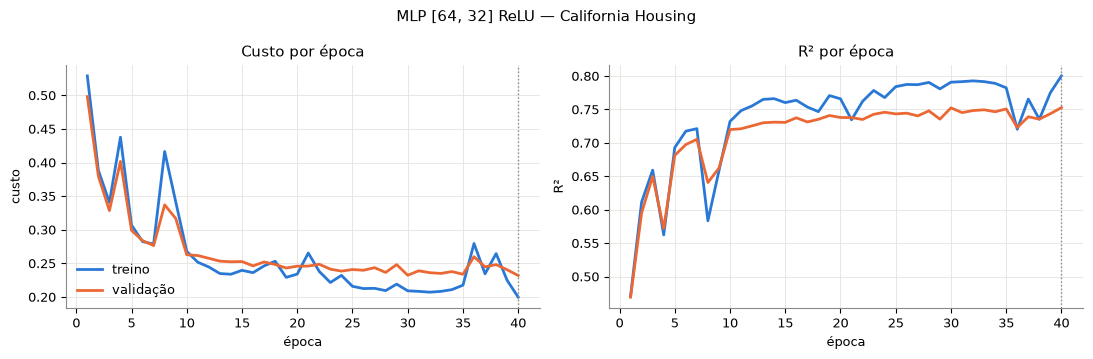

In [5]:
g.plot_curvas(historico, "MLP [64, 32] ReLU — California Housing")

## 4. Monitoramento: histogramas e normas

Os histogramas usam um **lote fixo de validação**, para que as épocas sejam comparáveis.
Os gradientes das ativações vêm de graça: depois do `backward()`, cada tensor intermediário já tem seu `.grad`.

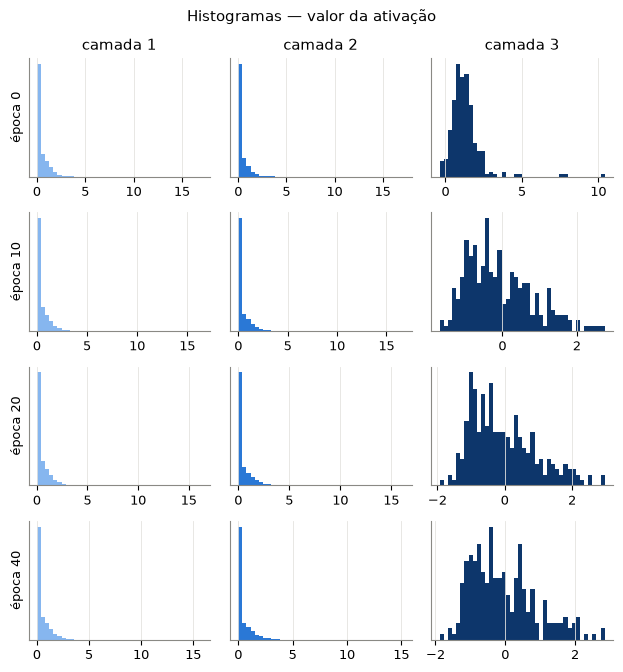

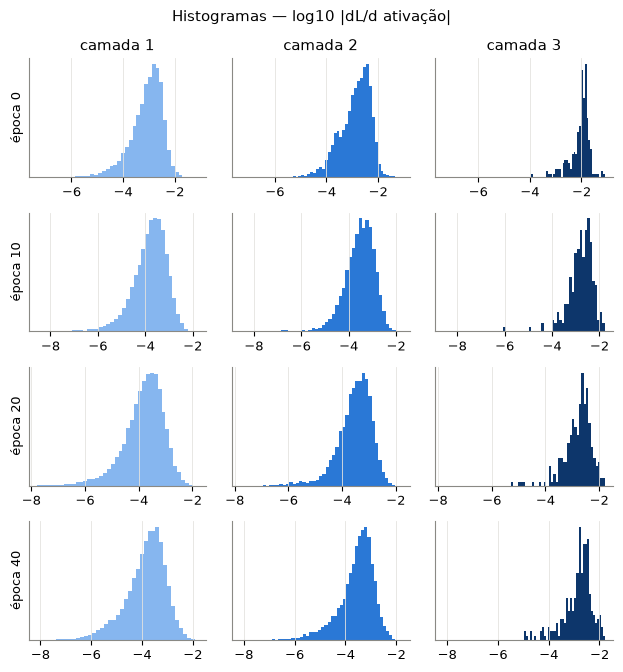

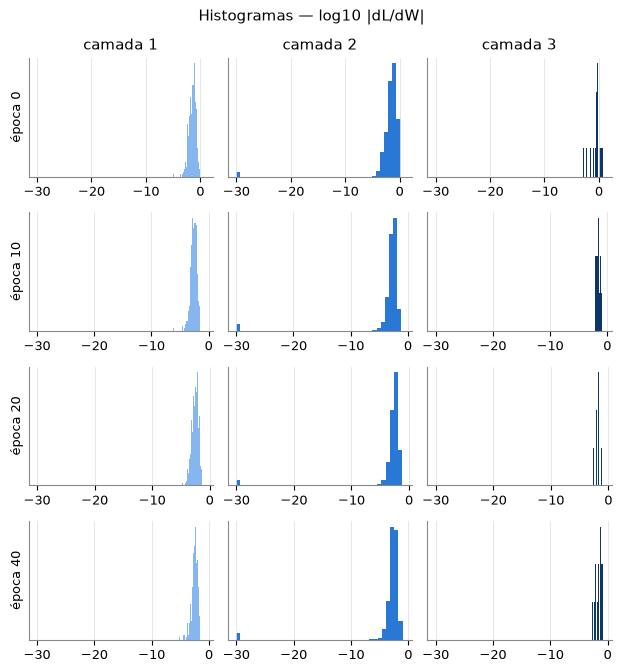

In [6]:
gg.plot_histogramas(historico, "ativacoes")
gg.plot_histogramas(historico, "grad_ativacoes")
gg.plot_histogramas(historico, "grad_pesos")

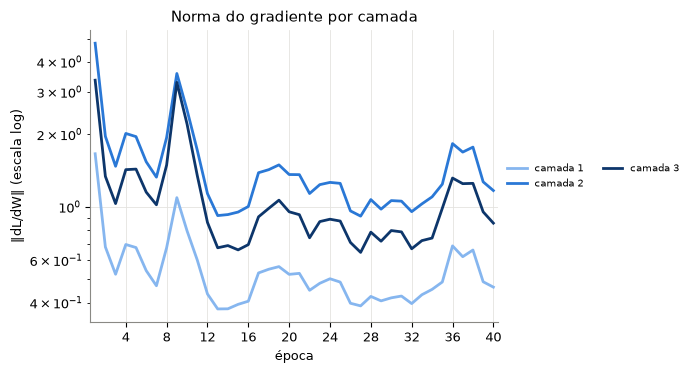

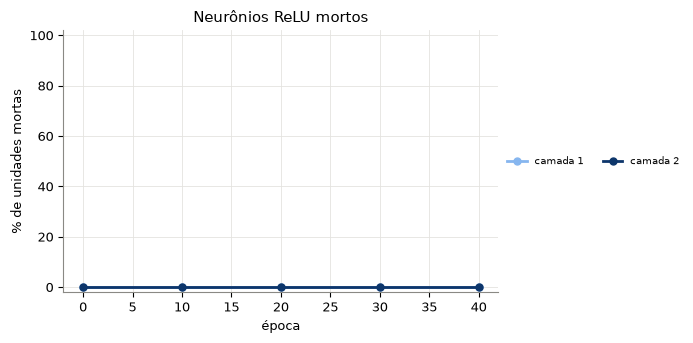

In [7]:
gg.plot_norma_grad_por_camada(historico)
gg.plot_relu_mortos(historico)

## 5. Regularização L2 (vitrine do autodiff)

`perda = perda + λ · Σ W²` — implementada em `treino.penalidade_l2` com 4 linhas.
**Nenhuma derivada foi escrita**: o motor deriva a penalidade sozinho.

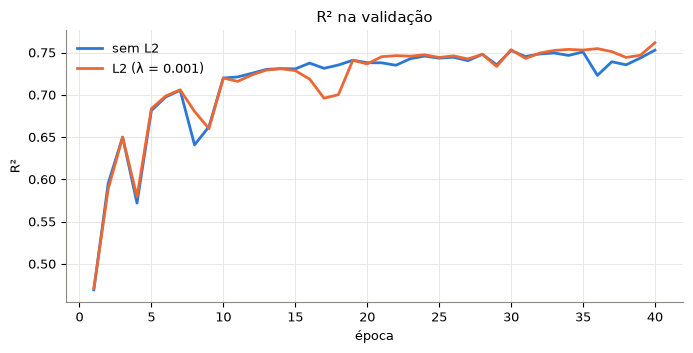

In [8]:
rede_l2 = MLP(config_rede)
config_l2 = dict(config_treino, lambda_l2=1e-3, verbose=False)
historico_l2 = treinar(rede_l2, dados, config_l2)
g.plot_comparacao({"sem L2": historico, "L2 (λ = 0.001)": historico_l2},
                  chave="metrica_val", titulo="R² na validação", ylabel="R²")

## 6. Exportar → importar → inferir

O JSON leva topologia, pesos **e a padronização** (médias e desvios de X e de y).
`carregar_modelo` reconstrói a rede; `prever` recebe dados **brutos** e devolve preços na escala original.

In [9]:
rede.padronizacao = dados["padronizacao"]
caminho = "modelos/regressao_california.json"
salvar_modelo(rede, caminho, nome_perda="mse",
              metricas={"r2_val": historico["metrica_val"][-1]})

importada = carregar_modelo(caminho)
previsto_original = rede.prever(dados["X_teste_bruto"])
previsto_importada = importada.prever(dados["X_teste_bruto"])
print("predições idênticas após importar?", np.allclose(previsto_original, previsto_importada))
print("primeiras previsões (US$ 100 mil):", previsto_importada[:5].ravel().round(3))
print("valores reais:                    ", dados["Y_teste_bruto"][:5].ravel().round(3))

predições idênticas após importar? True
primeiras previsões (US$ 100 mil): [0.74  1.556 2.456 1.397 3.151]
valores reais:                     [0.659 0.8   2.576 1.39  2.44 ]


## 7. Resultado final no teste (usado uma única vez)

MSE e MAE na escala original (unidade: US$ 100 mil). O R² não depende da escala.

modelo               MSE          R2         MAE
------------------------------------------------
MLP sem L2        0.3463      0.7370      0.4071
MLP com L2        0.3353      0.7453      0.4024


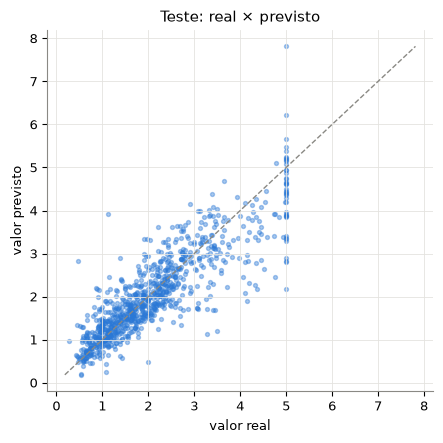

In [10]:
resultados = {
    "MLP sem L2": metricas_regressao(dados["Y_teste_bruto"], previsto_importada),
}
rede_l2.padronizacao = dados["padronizacao"]
resultados["MLP com L2"] = metricas_regressao(dados["Y_teste_bruto"], rede_l2.prever(dados["X_teste_bruto"]))
g.imprimir_tabela(resultados)
g.plot_regressao_real_vs_previsto(dados["Y_teste_bruto"].ravel(), previsto_importada.ravel())

## Conclusões
- O gradiente do motor bate com as diferenças finitas (erro relativo ~1e-10), inclusive com broadcasting e nó reutilizado.
- O MLP explica boa parte da variância do preço (R² no teste na tabela acima); treino e validação andam juntos, sem overfitting forte.
- Os histogramas mostram ativações e gradientes saudáveis em todas as camadas (He + ReLU), sem dissipação.
- A L2 foi adicionada sem escrever nenhuma derivada — só compondo `**`, `sum` e `+`.
- O modelo exportado reproduz exatamente as predições depois de importado, porque a padronização vai junto no arquivo.